# 5. Model comparison and recommendation

**Rubric section:** Model Evaluation and Comparison (20 pts).

Both models used the same seven features, the same train/test split, the same five
group-aware CV folds, the same selection metric (ROC-AUC), and the same stress test.
That makes this comparison fair.

`src/compare_models.py` reads each model's saved results. Nothing is retrained here.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800) -> None:
    """Display a saved figure from reports/figures."""
    display(Image(filename=str(FIGURES / name), width=width))

In [2]:
import compare_models

compare_models.main()

/Users/lucascoelho/Desktop/fall-2026/csce-478/project/human-vs-ai-ml-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


              Model                    Stage  accuracy  precision  recall     f1  roc_auc
Logistic regression                 CV train    0.9954     0.9955  0.9952 0.9953   0.9999
Logistic regression            CV validation    0.9951     0.9951  0.9952 0.9951   0.9998
Logistic regression            Held-out test    0.9944     0.9932  0.9956 0.9944   0.9998
Logistic regression Template-family hold-out    0.9888     0.9908  0.9836 0.9869   0.9984
      Random forest                 CV train    1.0000     1.0000  1.0000 1.0000   1.0000
      Random forest            CV validation    0.9975     0.9974  0.9976 0.9975   1.0000
      Random forest            Held-out test    0.9952     0.9926  0.9978 0.9952   0.9999
      Random forest Template-family hold-out    0.9859     0.9886  0.9794 0.9837   0.9984

logistic_regression_vs_random_forest: {'test_rows': 10000, 'logistic_regression_errors': 56, 'random_forest_errors': 48, 'both_wrong': 32, 'only_logistic_regression_wrong': 24, 'only_random

## Metric choice

- **Accuracy** works because the classes are exactly balanced.
- **Precision** (of texts called AI, how many really are AI) and **recall** (of AI texts,
  how many we catch) matter separately. Wrongly accusing a human writer is a costly mistake.
- **F1** balances precision and recall.
- **ROC-AUC** measures ranking quality at every threshold, not just 0.5.
- **Confusion matrices** show which kind of error each model makes.

In [3]:
table = pd.read_csv(METRICS / "model_comparison.csv")
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
table.pivot(index="Stage", columns="Model", values=metrics).round(4).reindex(
    ["CV train", "CV validation", "Held-out test", "Template-family hold-out"]
)

accuracy                         precision                            recall                \
Model                    Logistic regression Random forest Logistic regression Random forest Logistic regression Random forest   
Stage                                                                                                                            
CV train                              0.9954        1.0000              0.9955        1.0000              0.9952        1.0000   
CV validation                         0.9951        0.9975              0.9951        0.9974              0.9952        0.9976   
Held-out test                         0.9944        0.9952              0.9932        0.9926              0.9956        0.9978   
Template-family hold-out              0.9888        0.9859              0.9908        0.9886              0.9836        0.9794   

                                          f1                           roc_auc                
Model                    Logistic regression Random forest Logistic regression Random forest  
Stage                                                                                         
CV train                              0.9953        1.0000              0.9999        1.0000  
CV validation                         0.9951        0.9975              0.9998        1.0000  
Held-out test                         0.9944        0.9952              0.9998        0.9999  
Template-family hold-out              0.9869        0.9837              0.9984        0.9984

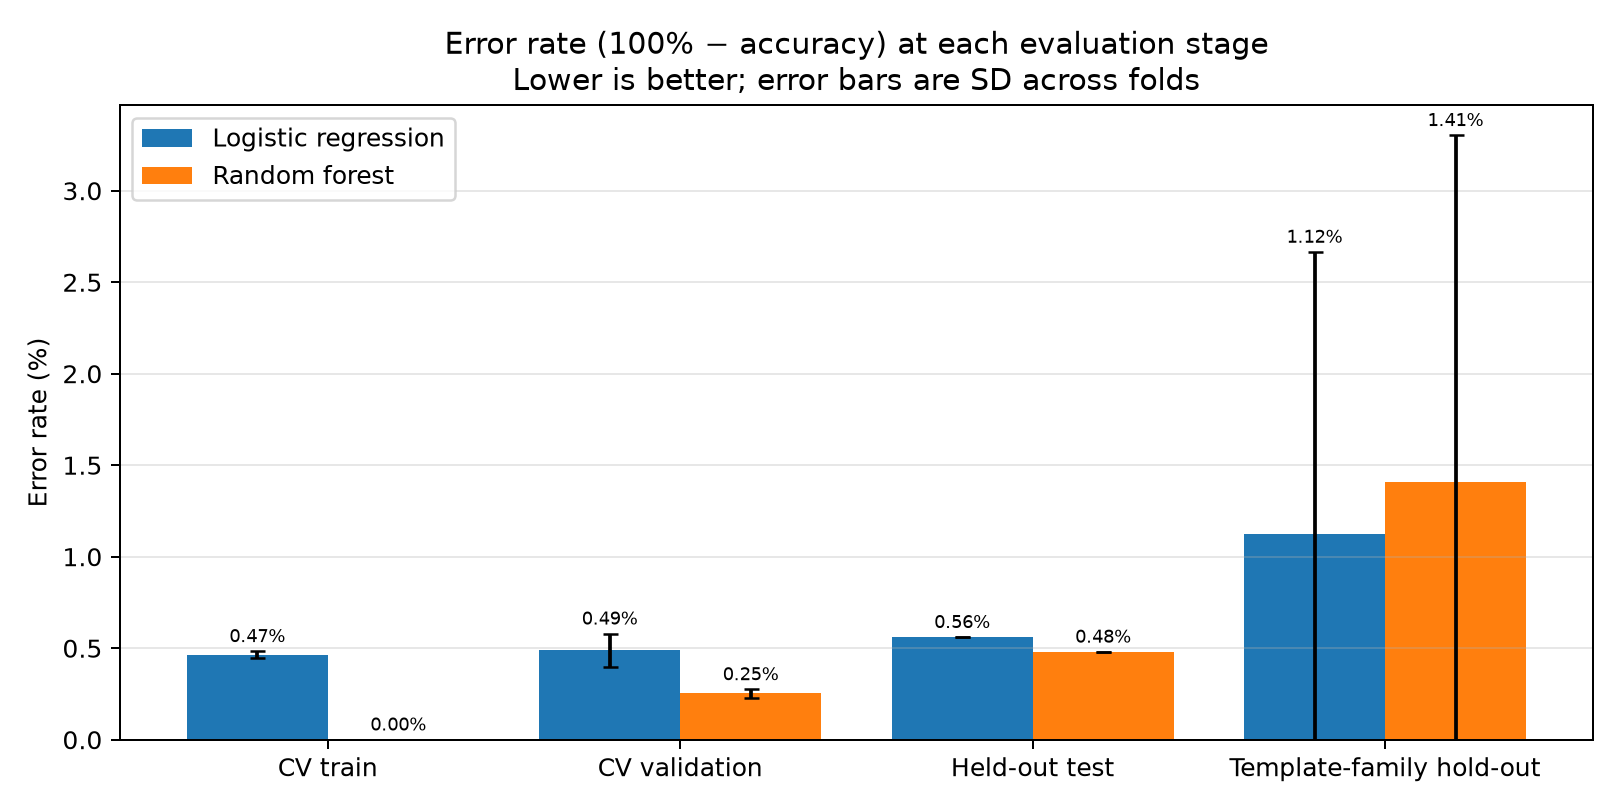

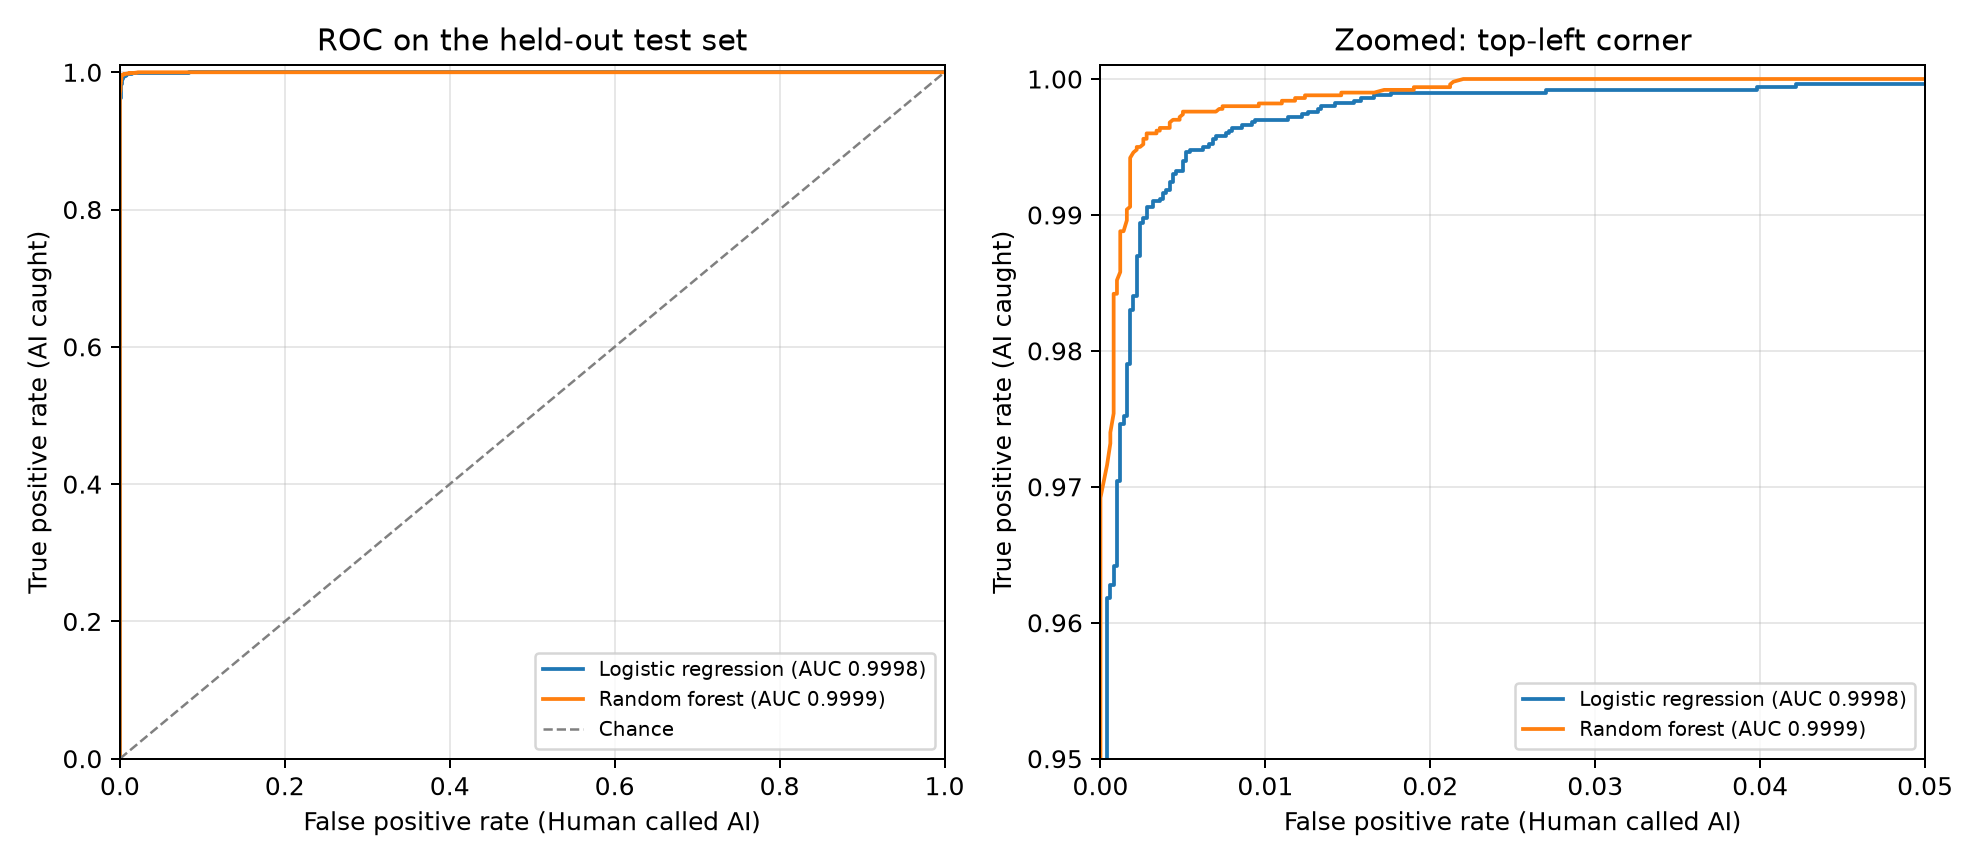

In [4]:
show("model_comparison_error_rates.png", 850)
show("model_comparison_roc.png", 950)

## Is the test-set difference real?

Both models were scored on the same 10,000 test texts. McNemar's test only counts texts
where exactly one model is wrong. If the models were equally good, those disagreements
would split about 50/50.

In [5]:
overlap = json.loads((METRICS / "model_comparison.json").read_text())
pair = overlap["logistic_regression_vs_random_forest"]
pd.Series({k: v for k, v in pair.items() if k != "both_wrong_text_ids"}).to_frame("value")

,value
test_rows,10000.000000
logistic_regression_errors,56.000000
random_forest_errors,48.000000
both_wrong,32.000000
only_logistic_regression_wrong,24.000000
only_random_forest_wrong,16.000000
mcnemar_exact_p_value,0.268187


## Error analysis: which texts fool the models?

In [6]:
from modeling import PROCESSED_PATH, SPLITS_PATH

lr = pd.read_csv(METRICS / "logistic_regression_test_predictions.csv")
rf = pd.read_csv(METRICS / "random_forest_test_predictions.csv")
splits = pd.read_csv(SPLITS_PATH, usecols=["Text_ID", "Template_Family_ID"])
both = lr.merge(rf, on=["Text_ID", "Label"], suffixes=("_LR", "_RF")).merge(splits, on="Text_ID")
both["LR_wrong"] = both["Predicted_Label_LR"] != both["Label"]
both["RF_wrong"] = both["Predicted_Label_RF"] != both["Label"]

by_family = both.groupby("Template_Family_ID").agg(
    label=("Label", lambda s: "AI" if s.iloc[0] == 1 else "Human"),
    test_rows=("Label", "size"),
    LR_errors=("LR_wrong", "sum"),
    RF_errors=("RF_wrong", "sum"),
)
by_family

,label,test_rows,LR_errors,RF_errors
Template_Family_ID,,,,
0,AI,1022,20,11
1,AI,992,0,0
2,AI,960,0,0
3,AI,1040,2,0
4,AI,986,0,0
5,Human,833,0,0
6,Human,831,0,0
7,Human,795,6,3
8,Human,791,0,0


In [7]:
processed = pd.read_csv(PROCESSED_PATH, usecols=["Text_ID", "Raw_Text", "Label_Name"])
shared = both[both["LR_wrong"] & both["RF_wrong"]].merge(processed, on="Text_ID")
print(f"Texts both models get wrong: {len(shared)}")
print(shared["Label_Name"].value_counts().to_string())
shared[["Text_ID", "Label_Name", "Template_Family_ID", "Probability_AI_LR", "Probability_AI_RF", "Raw_Text"]].head(8)

Texts both models get wrong: 32
Label_Name
Human    22
AI       10


,Text_ID,Label_Name,Template_Family_ID,Probability_AI_LR,Probability_AI_RF,Raw_Text
0,TXT_14945,Human,10,0.620794,0.740000,"When it comes to Business, there are several schools of thought-- The classi..."
1,TXT_15865,Human,10,0.685032,0.550000,"When it comes to Economics, there are several schools of thought. The classi..."
2,TXT_00179,Human,10,0.635775,0.743333,"When it comes to Cybersecurity, there are several schools of thought. The cl..."
3,TXT_06185,Human,10,0.772390,0.553333,"When it comes to Philosophy, there are several schools of thought. The appro..."
4,TXT_34151,Human,10,0.582445,0.780000,"When it comes to Productivity, there are several schools of thought. The cla..."
5,TXT_13636,Human,10,0.768708,0.663333,"When it comes to Cybersecurity, there are several schools of thought. The cl..."
6,TXT_39900,Human,10,0.977713,0.970000,"When it comes to Artificial Intelligence, there are several schools favors t..."
7,TXT_13174,Human,10,0.772390,0.553333,"When it comes to Psychology, there are several schools of thought. The the v..."


**What the errors show.** Almost every mistake from both models comes from two templates:
- **Family 10 (Human)** has the highest reading grade of the human templates (median about 12.2), so it's the closest human template to AI-style text.
- **Family 0 (AI)** has the lowest reading grade of the AI templates (median about 15.2), so it's the closest AI template to human-style text.

The other nine templates have zero or near-zero errors. The models fail where the two classes' writing styles overlap. Errors aren't random. That matches the feature
importances: reading grade level is the single strongest signal, and these are the two
templates where it's least clear-cut.

## Recommendation (draft for team review)

| | Logistic regression | Random forest |
| --- | --- | --- |
| Held-out test error | 0.56% (56 texts) | 0.48% (48 texts) |
| Difference significant? | McNemar p ≈ 0.27, so **no** | |
| Unseen-template error | **1.12%** | 1.41% |
| Train vs. validation gap | none | 100% vs. 99.75% |
| Interpretability | signed coefficients | importances only |
| Training cost (tuning grid) | about 10 s | about 3 min |

**Recommended: logistic regression.** The random forest's small test-set advantage isn't
statistically significant. It does slightly worse on writing templates it hasn't seen,
which is the closest thing we have to new data. Logistic regression is also simpler,
faster, and directly explainable. The random forest is useful as confirmation: a much
more flexible model found almost no extra signal, and it ranked the same features as
most important. So the linear boundary is not leaving much on the table.

**Caveat for both models.** Near-perfect scores show that this benchmark's 11 templates
are separable by simple style statistics. They do **not** show that real human writing
and real LLM writing can be separated this well.